In [1]:
import os
import sys
import warnings

sys.path.append("/path/to/GeneSPOT")
warnings.filterwarnings("ignore")

In [2]:
import math
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
from tqdm import tqdm
import seaborn as sns
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from statannotations.Annotator import Annotator
from adjustText import adjust_text
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

matplotlib.rcParams['font.family'] = 'Aptos'
matplotlib.rcParams['pdf.fonttype'] = 42

In [3]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything
from genespot.preprocess import preprocess_adata
from vendor.niche_embedding.MENDER import Mender
from genespot.genespot import build_graph, topk_similar
from genespot.optimal_transports import cal_ot_distance
from genespot.graph_representation import node2vec
from genespot.visualization import plot_clusters_with_density_and_edges, create_cmap

random_state = 42
seed_everything(random_state)

In [4]:
DATA_DIR = Path('/path/to/GeneSPOT/data')
RES_DIR = Path('/path/to/GeneSPOT/reproduce/fig2/res')
OUTPUTS_DIR = Path('/path/to/GeneSPOT/reproduce/fig2/outputs')

os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

In [5]:
adata = sc.read_h5ad(DATA_DIR / 'mPFC/Dataset11.h5ad')
adata.layers["raw"] = adata.X.copy()
annotations = ['Layer I', 'Layer II/III', 'Layer V', 'Layer VI']
adata.obs['annotations'] = adata.obs['gt'].apply(lambda x: annotations[x-1])
adata.obsm['spatial_3d'] = np.zeros((adata.shape[0], 3))
adata.obsm['spatial_3d'][:, :2] = adata.obsm['spatial']
slices = ['BZ5', 'BZ9', 'BZ14']
adata.uns['slice_id_colors'] = ['#6494c0', '#e96858', '#f5bb6c']

adata.uns['gt_colors'] = ["#e07a5f", "#3d405b", "#81b29a", "#f2cc8f"]
adata.uns['annotations_colors'] = ["#e07a5f", "#3d405b", "#81b29a", "#f2cc8f"]
adata.uns['ct_colors'] = ["#98c1d9","#2a9d8f","#e9c46a","#f4a261","#e76f51", 
                          "#234888", "#a8dadc","#b388eb","#bb3e03","#52b69a", 
                          "#e9d8a6", "#f19c79", "#DBC9D8", "#A4277C", "#D79739"]

In [6]:
adata.obs['slice_id'].value_counts()

slice_id
BZ14    1088
BZ9     1053
BZ5     1049
Name: count, dtype: int64

In [7]:
adata[adata.obs['slice_id'] == "BZ5"].obs['annotations'].value_counts()

annotations
Layer V         449
Layer VI        347
Layer II/III    167
Layer I          86
Name: count, dtype: int64

In [8]:
adata[adata.obs['slice_id'] == "BZ9"].obs['annotations'].value_counts()

annotations
Layer V         503
Layer VI        353
Layer II/III    115
Layer I          82
Name: count, dtype: int64

In [9]:
adata[adata.obs['slice_id'] == "BZ14"].obs['annotations'].value_counts()

annotations
Layer VI        461
Layer V         435
Layer II/III    158
Layer I          34
Name: count, dtype: int64

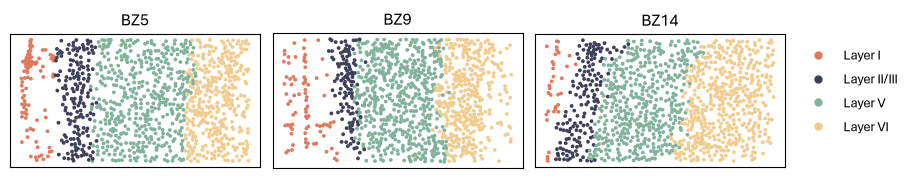

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3))
for i, slice in enumerate(slices):
    slice_adata = adata[adata.obs['slice_id'] == slice]
    # scatter_3d(slice_adata, c='annotations', s=10, ax=axs[i], basis='spatial', title='')
    sc.pl.embedding(slice_adata, basis='spatial', color='annotations', s=30, ax=axs[i], show=False)
    axs[i].set_title(slice)
    axs[i].set_xlabel('')
    axs[i].set_ylabel('')
    axs[i].set_xticks([], [])
    axs[i].set_yticks([], [])
    axs[i].set_aspect(1)

gt_legends = []
for i, gt in enumerate(annotations):
    gt_legends.append(
        Line2D([0], [0], marker='o', color=adata.uns[f'annotations_colors'][i], 
               markerfacecolor=None, linestyle='None', markersize=5,
               label=gt)
    )
plt.legend(
    handles=gt_legends, title='',
    title_fontsize=12, bbox_to_anchor=(1.5, 1),
    fontsize=10,
    loc="upper right", frameon=False, ncols=1)

plt.subplots_adjust(wspace=0.05)
plt.savefig(OUTPUTS_DIR / 'fig2b.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

In [9]:
training_slices = ['BZ9', 'BZ14']
testing_slices = ['BZ5']
training_adata = adata[adata.obs['slice_id'].isin(training_slices)]
testing_adata = adata[adata.obs['slice_id'].isin(testing_slices)]

if not os.path.exists(RES_DIR / 'training_adata.h5ad'):
    mender = Mender(adata=training_adata, ct_obs='ct', batch_obs='slice_id', random_state=42)
    mender.init(scale=6, radius=150)
    mender.run(target_k=-0.5, key_added='MENDER')

    ari = adjusted_rand_score(training_adata.obs['annotations'], training_adata.obs['MENDER'])
    print(f'{ari:.4f}')
    sc.pp.neighbors(training_adata, use_rep='MENDER_M_pca', random_state=random_state)
    sc.tl.umap(training_adata, n_components=3, random_state=random_state)
    training_adata.write_h5ad(RES_DIR / 'training_adata.h5ad')
else:
    training_adata = sc.read_h5ad(RES_DIR / 'training_adata.h5ad')

In [10]:
training_adata.var['feature_names'] = training_adata.var_names.values.tolist()
training_adata.var['feature_types'] = ['Gene'] * training_adata.shape[1]

if os.path.exists(RES_DIR / 'running_adata.h5ad'):
    # Note: Results may vary slightly across different run environments, so we load the data instead of re-running the analysist.
    cost, running_adata = build_graph(
        training_adata,
        coarsen=True, coarsen_key='annotations',
        
        feature_expression_layer='raw', 
        feature_aggregate_func='mean',
        
        add_landmarks=True,
        landmark_subset=False,
        landmark_expression_value=1.,
        non_landmark_expression_value=0.,
        landmark_prefix='SpatialLandmark',
        
        n_neighbors=20,
        use_rep='MENDER_M_pca',
        coarsen_method='paga_guided_umap',
        random_state=random_state
    )
    gstd = cal_ot_distance(running_adata.X, cost, processes=None)

    feature_embedding, _, loss = node2vec(
        gstd, 
        n_neighbors=10,
        p=1, q=0.5,
        epochs=200,
        lr=1e-2,
        device='cpu',
        norm=True
    )
    gdata = sc.AnnData(running_adata.X.T)
    gdata.obsm['feature_embedding'] = feature_embedding
    gdata.obs_names = running_adata.var['feature_names']
    gdata.obs['feature_names'] = running_adata.var['feature_names']
    gdata.obs['feature_types'] = running_adata.var['feature_types']
    gdata.obs['feature_annotations'] = running_adata.var['feature_annotations']
    
    sc.pp.neighbors(gdata, random_state=random_state, use_rep='feature_embedding')
    sc.tl.umap(gdata, random_state=random_state)
    sc.tl.leiden(gdata, resolution=4, random_state=random_state)

else:
    gdata = sc.read_h5ad(RES_DIR / 'gdata.h5ad')
gene_clusters = gdata.obs['leiden'].cat.categories

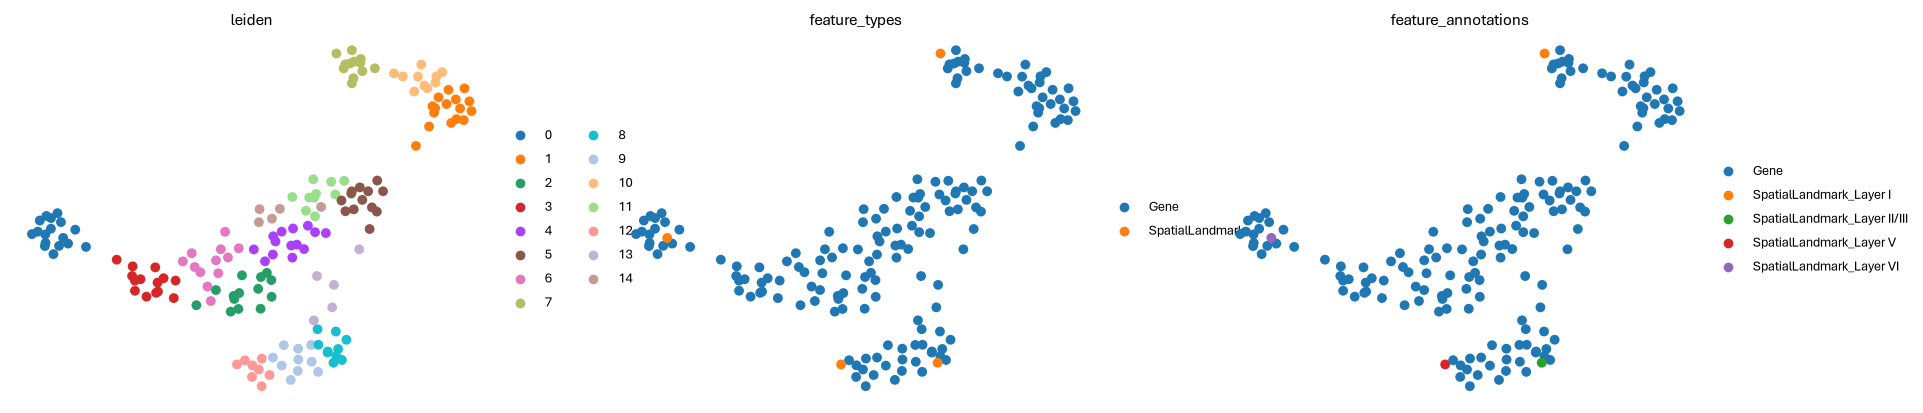

In [11]:
sc.pl.umap(gdata, color=['leiden', 'feature_types', 'feature_annotations'], edges=False, frameon=False, size=200, alpha=1)

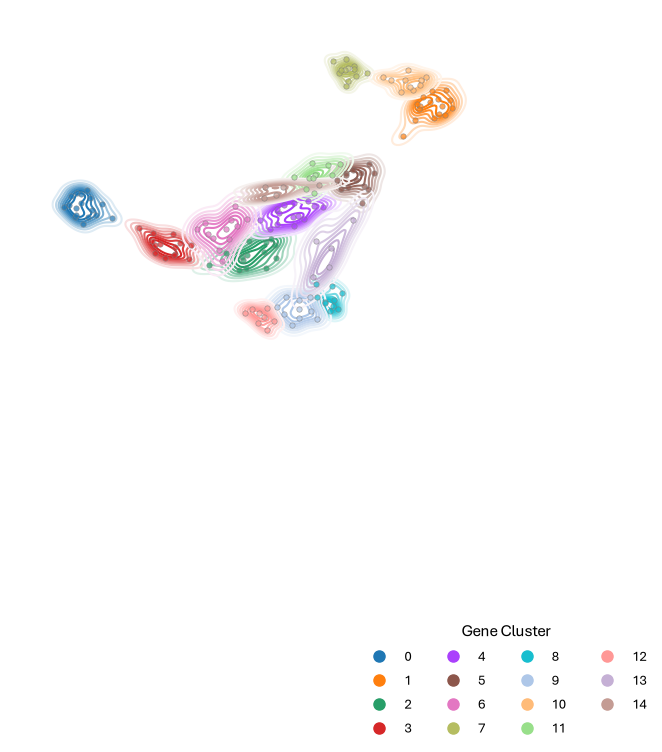

In [12]:
plot_clusters_with_density_and_edges(
    gdata, cluster_key='leiden', save=True, delta=2,
    contour_linewidths=1.5,
    legend=True, save_name='fig2c', save_path=OUTPUTS_DIR,
    scatter_s=15,
    scatter_edgecolor='grey',
    draw_edges=False
)

In [13]:
for gcid, gc in enumerate(gene_clusters):
    selected_genes = gdata[(gdata.obs['feature_types'] == 'Gene') & (gdata.obs['leiden'] == gc)].obs_names
    adata.obs[f'GC{gc}'] = adata[:, selected_genes].layers['raw'].mean(axis=1)

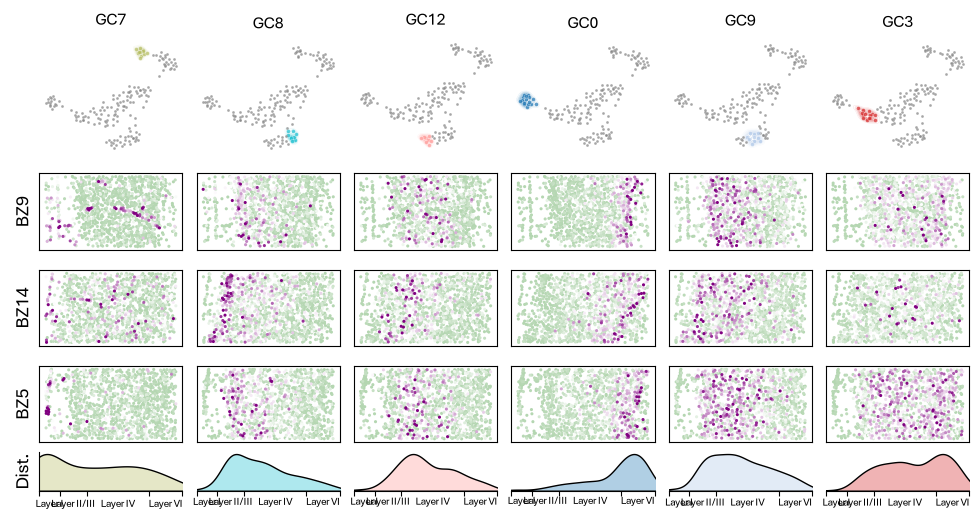

In [14]:
# selected_clusters = gene_clusters
selected_clusters = list(map(str, [7, 8, 12, 0, 9, 3]))
fig, axs = plt.subplots(
    5, len(selected_clusters), 
    figsize=(2 * len(selected_clusters), 6),
    gridspec_kw={'height_ratios': [1.4, 1, 1, 1, 0.4]}
)

cmap = create_cmap(['#b4d6b1', 'white', 'purple'], [0.0, 0.25, 1.0])
spatial_x = testing_adata.obsm['spatial'][:, 0]
x_min =  testing_adata.obsm['spatial'][:, 0].min()
x_max =  testing_adata.obsm['spatial'][:, 0].max()

y_min =  testing_adata.obsm['spatial'][:, 1].min()
y_max =  testing_adata.obsm['spatial'][:, 1].max()

l1_max = (testing_adata[testing_adata.obs['annotations'] == 'Layer I'].obsm['spatial'][:, 0].max() - x_min) / (x_max - x_min)
l23_max = (testing_adata[testing_adata.obs['annotations'] == 'Layer II/III'].obsm['spatial'][:, 0].max() - x_min) / (x_max - x_min)
l5_max = (testing_adata[testing_adata.obs['annotations'] == 'Layer V'].obsm['spatial'][:, 0].max() - x_min) / (x_max - x_min)
l6_max = (testing_adata[testing_adata.obs['annotations'] == 'Layer VI'].obsm['spatial'][:, 0].max() - x_min) / (x_max - x_min)

# Adding the boundaries and labels at the center of the defined regions
boundary_positions = [0.0, l1_max, l23_max, l5_max, 1.0]
labels_positions = [l1_max / 2, (l1_max + l23_max) / 2, (l23_max + l5_max) / 2, (l5_max + 1.0) / 2]
labels = ['Layer I', 'Layer II/III', 'Layer IV', 'Layer VI']
spatial_x = (spatial_x - spatial_x.min()) / (spatial_x.max() - spatial_x.min())

##### 1. Gene Embedding: UMAP with KDE #####
for i, gc in enumerate(selected_clusters):
    plot_clusters_with_density_and_edges(
        gdata, cluster_key='leiden', save=False,
        cluster_subset=str(gc), legend=False,
        ax=axs[0][i], show=False,
        
        contour_linewidths=0.3,
        scatter_s=8, 
        scatter_linewidths=0.3,

        scatter_nan_linewidths=0.1,
        draw_edges=False,
        na_color='grey',
        scatter_nan_s=4,
    )
    axs[0][i].set_title(f'GC{gc}', pad=10)
    axs[0][i].set_aspect('equal', adjustable='box')

    
for gcid, gc in enumerate(selected_clusters):
    for sid, slice in enumerate(training_slices + testing_slices):
        slice_adata = adata[adata.obs['slice_id'] == slice]
        sc.pl.embedding(
            slice_adata, color=f'GC{gc}', basis='spatial', cmap=cmap, 
            vmax='p99', # vmin='p1',
            show=False, ax=axs[sid+1][gcid], size=20, colorbar_loc=None)
        axs[sid+1][gcid].set_title('')
        axs[sid+1][gcid].set_xlabel('')
        axs[sid+1][gcid].set_ylabel('')
        axs[sid+1][gcid].set_aspect('equal', adjustable='box')
    
        if gcid == 0:
            axs[sid+1][gcid].set_ylabel(slice, fontsize=14)

    gene_expression = adata[adata.obs['slice_id'].isin(testing_slices)].obs[f'GC{gc}'].values
    sns.kdeplot(
        x=spatial_x,
        weights=gene_expression,
        fill=True,
        alpha=0.35,
        multiple='stack',
        color=gdata.uns['leiden_colors'][int(gc)],
        ax=axs[-1][gcid]
    )

    axs[-1][gcid].set_yticks([], [])
    axs[-1][gcid].set_xlim(-0.0, 1.0)
    axs[-1][gcid].set_xticks(boundary_positions)
    axs[-1][gcid].set_xticklabels(['', '', '', '', ''], rotation=45, fontsize=8)
    axs[-1][gcid].set_ylabel('')

    axs[-1][gcid].spines['top'].set_visible(False)
    axs[-1][gcid].spines['right'].set_visible(False)
    
    if gcid == 0:
        axs[-1][gcid].set_ylabel('Dist.', fontsize=14)
        axs[-1][gcid].spines['left'].set_visible(True)
    else:
        axs[-1][gcid].set_ylabel('')
        axs[-1][gcid].spines['left'].set_visible(False)

    for label_pos, label in zip(labels_positions, labels):
        axs[-1][gcid].text(
            label_pos, -0.2, label, 
            ha='center', va='top',
            fontsize=8
        )

plt.subplots_adjust(wspace=0.1, hspace=0)
plt.savefig(OUTPUTS_DIR / 'fig2d.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

['Bgn']
['Smad3']


['Egr4']
['Drd1']
['Parm1']
['Arx']
['Ngb']
['Adgrl2']


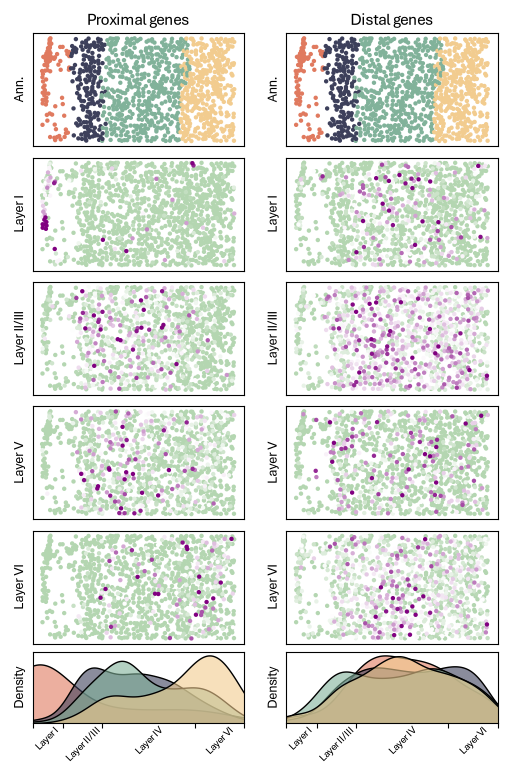

In [15]:
fig, axs = plt.subplots(
    6, 2, figsize=(6, 9),
    gridspec_kw={'height_ratios': [1, 1, 1, 1, 1, 0.6]}
)
psize = 40
layer_ = 'raw'

spatial_x = testing_adata.obsm['spatial'][:, 0]
x_min =  testing_adata.obsm['spatial'][:, 0].min()
x_max =  testing_adata.obsm['spatial'][:, 0].max()
y_min =  testing_adata.obsm['spatial'][:, 1].min()
y_max =  testing_adata.obsm['spatial'][:, 1].max()

l1_min = testing_adata[testing_adata.obs['annotations'] == annotations[0]].obsm['spatial'][:, 0].min()
l1_max = testing_adata[testing_adata.obs['annotations'] == annotations[0]].obsm['spatial'][:, 0].max()
l23_max = testing_adata[testing_adata.obs['annotations'] == annotations[1]].obsm['spatial'][:, 0].max()
l5_max = testing_adata[testing_adata.obs['annotations'] == annotations[2]].obsm['spatial'][:, 0].max()
l6_max = testing_adata[testing_adata.obs['annotations'] == annotations[3]].obsm['spatial'][:, 0].max()
# Adding the boundaries and labels at the center of the defined regions
boundary_positions = [l1_min, l1_max, l23_max, l5_max, l6_max]
labels_positions = [(l1_max - l1_min) / 2, (l1_max + l23_max) / 2, (l23_max + l5_max) / 2, (l5_max + l6_max) / 2]

for c, col in enumerate(['top', 'bottom']):
    sc.pl.embedding(testing_adata, color='annotations', basis='spatial', ax=axs[0][c], show=False, legend_loc=None, size=psize,)
    axs[0][c].set_aspect('equal', adjustable='box')
    axs[0][c].set_ylabel('Ann.')
    axs[0][c].set_xlabel('')
    axs[0][c].set_title(
        'Proximal genes' if col == 'top' else 'Distal genes'
    )

    # spatial_x = (spatial_x - spatial_x.min()) / (spatial_x.max() - spatial_x.min())
    for i, domain in enumerate(annotations):
        markers = topk_similar(
            f'SpatialLandmark_{domain}',
            gdata=gdata,
            embedding_key='feature_embedding', 
            ftype='Gene', 
            ftype_key='feature_types',
            smaller_is_better= col != 'top', 
            metric='cosine_similarity', 
            n=1,
            metric_threshold=0
        ).index.tolist()
        print(markers)
        
        testing_adata.obs[f'{domain}_{col}'] = testing_adata[:, markers].layers['raw'].mean(1)
        sc.pl.embedding(
            testing_adata,
            color=f'{domain}_{col}',
            # color=markers[i],
            basis='spatial',
            ax=axs[i+1][c],
            layer=layer_,
            vmax='p99', # vmin='p1',
            show=False, cmap=cmap,
            colorbar_loc=None, size=psize
        )
        gene_expression = testing_adata.obs[f'{domain}_{col}'].values.flatten()
        axs[i+1][c].set_title('')
        axs[i+1][c].set_ylabel(annotations[i])
        axs[i+1][c].set_xlabel('')
        axs[i+1][c].set_aspect('equal', adjustable='box')  # 'box' 可选 'datalim'

        sns.kdeplot(
            x=spatial_x,
            weights=gene_expression,
            fill=True,
            alpha=0.6,
            multiple='stack',
            color=slice_adata.uns['gt_colors'][i],
            ax=axs[-1][c]
        )
        axs[-1][c].set_yticks([], [])
        axs[-1][c].set_xlim(x_min, x_max)
        axs[-1][c].set_xticks(boundary_positions)
        # axs[-1][c].set_xticklabels(['', 'L1', 'L2/3', 'L5', 'L6'], rotation=45, fontsize=8)
        axs[-1][c].set_xticklabels(['', '', '', '', ''])
        
    for label_pos, label in zip(labels_positions, labels):
        axs[-1][c].text(
            label_pos, -0., label, 
            ha='center', va='top',
            fontsize=8, rotation=45
        )

plt.subplots_adjust(hspace=0.05, wspace=0.2)
plt.savefig(OUTPUTS_DIR / 'fig2e.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

PCA0_top 8.142129e-11
PCA0_bottom 0.20838876
PCA0_all 0.062746756


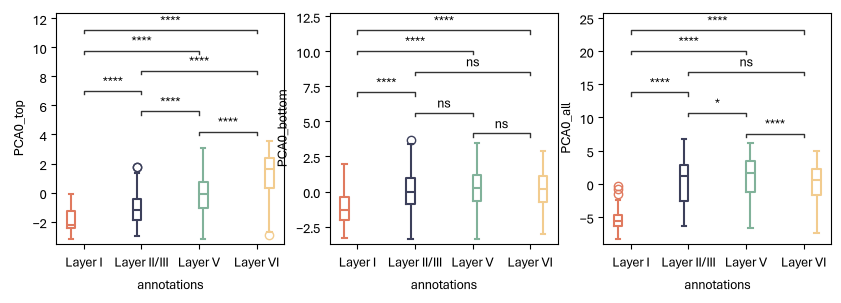

PCA1_top 0.009949555
PCA1_bottom 0.44132927
PCA1_all 0.03334676


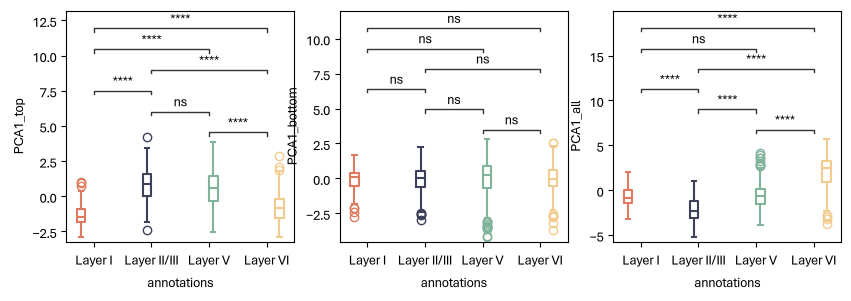

In [16]:
# PCA w/ nearest N genes
n_top = 20
top_markers = []
bottom_markers = []
marker_score = []
selected_features = adata.var_names.values
hue_cmap = dict(zip(annotations, adata.uns['annotations_colors']))

for domain in annotations:
    markers = topk_similar(f'SpatialLandmark_{domain}', gdata, embedding_key='feature_embedding', ftype='Gene', ftype_key='feature_types', n=adata.shape[1], smaller_is_better=False, metric='cosine_similarity')
    markers = markers[['metric']].reset_index()
    markers.columns = ['Gene', 'Score']
    markers = markers.set_index('Gene')
    marker_score.append(
        markers.loc[selected_features]['Score'].values.reshape(-1, ).tolist()
    )
marker_score = np.array(marker_score).std(axis=0)
top_marker_ind = np.argsort(marker_score)[::-1][:n_top]
bottom_marker_ind = np.argsort(marker_score)[:n_top]
top_markers = selected_features[top_marker_ind].tolist()
bottom_markers = selected_features[bottom_marker_ind].tolist()

adata_ = testing_adata.copy()
adata_.X = adata_.layers['raw']
top_adata = adata_[:, top_markers].copy()
top_adata = preprocess_adata(top_adata, scale=True)
adata_.obsm['PCA_top'] = PCA(n_components=2, random_state=random_state).fit_transform(top_adata.X)
adata_.obs['PCA0_top'] = adata_.obsm['PCA_top'][:, 0]
adata_.obs['PCA1_top'] = adata_.obsm['PCA_top'][:, 1]

bottom_adata = adata_[:, bottom_markers].copy()
bottom_adata = preprocess_adata(bottom_adata, scale=True)
adata_.obsm['PCA_bottom'] = PCA(n_components=2, random_state=random_state).fit_transform(bottom_adata.X)
adata_.obs['PCA0_bottom'] = adata_.obsm['PCA_bottom'][:, 0]
adata_.obs['PCA1_bottom'] = adata_.obsm['PCA_bottom'][:, 1]

all_adata = preprocess_adata(adata_, scale=True)
adata_.obsm['PCA_all'] = PCA(n_components=2, random_state=random_state).fit_transform(all_adata.X)
adata_.obs['PCA0_all'] = adata_.obsm['PCA_all'][:, 0]
adata_.obs['PCA1_all'] = adata_.obsm['PCA_all'][:, 1]

from statannotations.Annotator import Annotator
fig, axs = plt.subplots(1, 3, figsize=(10, 3))

for i, c in enumerate(['PCA0_top', 'PCA0_bottom', 'PCA0_all']):
    sns.boxplot(
        adata_.obs,
        x='annotations', 
        y=c, 
        orient='v', 
        ax=axs[i], 
        width=0.6,
        hue='annotations',
        legend=False, 
        palette=hue_cmap,
        fill=False
    )
    
    pairs = list(itertools.combinations(annotations, 2))[::-1]
    order = annotations
    annotator = Annotator(axs[i], pairs, data=adata_.obs, x='annotations', y=c, order=order, verbose=False)
    annotator.configure(test='t-test_ind', text_format='star',line_height=0.03, line_width=1)
    annotator.apply_and_annotate()

    sigs = []
    for j in range(len(pairs)):
        sigs.append(annotator.annotations[j].data.pvalue)
    print(c, np.mean(sigs))

plt.show()

from statannotations.Annotator import Annotator
fig, axs = plt.subplots(1, 3, figsize=(10, 3))

for i, c in enumerate(['PCA1_top', 'PCA1_bottom', 'PCA1_all']):
    sns.boxplot(
        adata_.obs,
        x='annotations', 
        y=c, 
        orient='v', 
        ax=axs[i], 
        width=0.6,
        hue='annotations',
        legend=False, 
        palette=hue_cmap,
        fill=False
    )
    
    pairs = list(itertools.combinations(annotations, 2))[::-1]
    order = annotations
    annotator = Annotator(axs[i], pairs, data=adata_.obs, x='annotations', y=c, order=order, verbose=False)
    annotator.configure(test='t-test_ind', text_format='star',line_height=0.03, line_width=1)
    annotator.apply_and_annotate()
    sigs = []
    for j in range(len(pairs)):
        sigs.append(annotator.annotations[j].data.pvalue)
    print(c, np.mean(sigs))

plt.show()

--- Layer VI ---
  Layer V vs Layer VI: p=3.14e-95
  Layer II/III vs Layer VI: p=4.17e-37
  Layer II/III vs Layer V: p=1.70e-23
  Layer I vs Layer VI: p=4.14e-117
  Layer I vs Layer V: p=3.52e-78
  Layer I vs Layer II/III: p=4.25e-111
--- Layer VI ---
  Layer V vs Layer VI: p=1.32e-119
  Layer II/III vs Layer VI: p=6.18e-4
  Layer II/III vs Layer V: p=4.76e-93
  Layer I vs Layer VI: p=3.37e-99
  Layer I vs Layer V: p=2.83e-81
  Layer I vs Layer II/III: p=1.29e-13
--- Layer VI ---
  Layer V vs Layer VI: p=5.52e-2
  Layer II/III vs Layer VI: p=1.58e-2
  Layer II/III vs Layer V: p=1.79e-31
  Layer I vs Layer VI: p=1.18e-1
  Layer I vs Layer V: p=8.63e-44
  Layer I vs Layer II/III: p=2.06e-39
--- Layer VI ---
  Layer V vs Layer VI: p=6.88e-2
  Layer II/III vs Layer VI: p=4.90e-3
  Layer II/III vs Layer V: p=2.92e-1
  Layer I vs Layer VI: p=2.74e-2
  Layer I vs Layer V: p=3.30e-2
  Layer I vs Layer II/III: p=9.17e-2


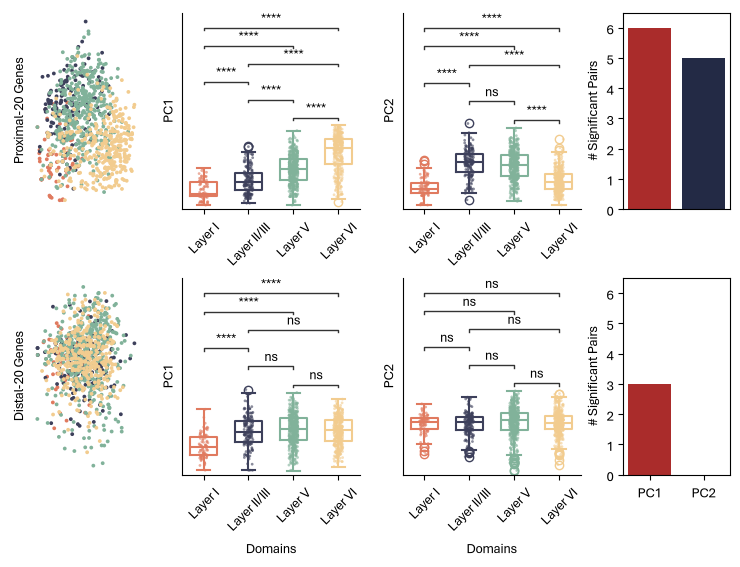

In [17]:
fig, axs = plt.subplots(
    2, 4, figsize=(9, 6),
    gridspec_kw={'width_ratios': [0.6, 1, 1, 0.6]},
)
pairs = list(itertools.combinations(annotations, 2))[::-1]
order = annotations

sc.pl.embedding(adata_, color='annotations', basis='PCA_top', size=30, ax=axs[0][0], show=False, legend_loc=None, title='', palette=hue_cmap)
axs[0][0].set_xlabel('')
axs[0][0].set_ylabel(f'Proximal-{n_top} Genes')
axs[0][0].spines['top'].set_visible(False)
axs[0][0].spines['right'].set_visible(False)
axs[0][0].spines['left'].set_visible(False)
axs[0][0].spines['bottom'].set_visible(False)
# axs[0][0].set_aspect(1)

sns.boxplot(adata_.obs, x='annotations', y='PCA0_top', orient='v', ax=axs[0][1], width=0.6, palette=hue_cmap, fill=False)
sns.stripplot(adata_.obs, x='annotations', y='PCA0_top', orient='v', ax=axs[0][1], palette=hue_cmap, alpha=0.6, size=2)
axs[0][1].set_xlabel('')
axs[0][1].set_ylabel('PC1')
axs[0][1].set_xticks([], [])
axs[0][1].set_yticks([], [])
axs[0][1].set_xticks([0, 1, 2, 3], annotations, rotation=45)
axs[0][1].spines['top'].set_visible(False)
axs[0][1].spines['right'].set_visible(False)

annotator = Annotator(axs[0][1], pairs, data=adata_.obs, x='annotations', y='PCA0_top', order=order, verbose=False)
annotator.configure(test='t-test_ind', text_format='star',line_height=0.03, line_width=1)
annotator.apply_and_annotate()
print(f'--- {label} ---')
for _pair, _ann in zip(pairs, annotator.annotations):
    _d = _ann.data
    _n1 = (adata_.obs['annotations'] == _pair[0]).sum()
    _n2 = (adata_.obs['annotations'] == _pair[1]).sum()
    _df = int(_n1 + _n2 - 2)
    from scipy import stats as _stats
    import numpy as np, math as _math
    _logp = np.log10(2) + _stats.t.logsf(abs(_d.stat_value), _df)
    _mant = 10 ** (_logp - math.floor(_logp))
    _exp = int(math.floor(_logp))
    _pstr = f'{_mant:.2f}e{_exp}'
    print(f'  {_pair[0]} vs {_pair[1]}: p={_pstr}')
pca0_sigs = []
for j in range(len(pairs)):
    pca0_sigs.append(annotator.annotations[j].data.pvalue < 0.05)
pca0_sigs_mean = np.sum(pca0_sigs)

sns.boxplot(adata_.obs, x='annotations', y='PCA1_top', orient='v', ax=axs[0][2], width=0.6, palette=hue_cmap, fill=False)
sns.stripplot(adata_.obs, x='annotations', y='PCA1_top', orient='v', ax=axs[0][2], palette=hue_cmap, alpha=0.6, size=2)
axs[0][2].set_xlabel('')
axs[0][2].set_ylabel('PC2')
axs[0][2].set_xticks([], [])
axs[0][2].set_yticks([], [])
axs[0][2].set_xticks([0, 1, 2, 3], annotations, rotation=45)
axs[0][2].spines['top'].set_visible(False)
axs[0][2].spines['right'].set_visible(False)

annotator = Annotator(axs[0][2], pairs, data=adata_.obs, x='annotations', y='PCA1_top', order=order, verbose=False)
annotator.configure(test='t-test_ind', text_format='star',line_height=0.03, line_width=1)
annotator.apply_and_annotate()
print(f'--- {label} ---')
for _pair, _ann in zip(pairs, annotator.annotations):
    _d = _ann.data
    _n1 = (adata_.obs['annotations'] == _pair[0]).sum()
    _n2 = (adata_.obs['annotations'] == _pair[1]).sum()
    _df = int(_n1 + _n2 - 2)
    from scipy import stats as _stats
    import numpy as np, math as _math
    _logp = np.log10(2) + _stats.t.logsf(abs(_d.stat_value), _df)
    _mant = 10 ** (_logp - math.floor(_logp))
    _exp = int(math.floor(_logp))
    _pstr = f'{_mant:.2f}e{_exp}'
    print(f'  {_pair[0]} vs {_pair[1]}: p={_pstr}')
pca1_sigs = []
for j in range(len(pairs)):
    pca1_sigs.append(annotator.annotations[j].data.pvalue < 0.05)
pca1_sigs_mean = np.sum(pca1_sigs)

axs[0][3].bar(range(2), [pca0_sigs_mean, pca1_sigs_mean], color=['#aa2c2b', '#232a45'])
axs[0][3].set_ylabel('# Significant Pairs')
axs[0][3].set_xticks([0, 1], ['PC1', 'PC2'])
axs[0][3].set_xticks([], [])
axs[0][3].set_ylim(0, 6.5)

sc.pl.embedding(adata_, color='annotations', basis='PCA_bottom', size=30, ax=axs[1][0], show=False, legend_loc=None, title='')
axs[1][0].set_xlabel('')
axs[1][0].set_ylabel(f'Distal-{n_top} Genes')
axs[1][0].spines['top'].set_visible(False)
axs[1][0].spines['right'].set_visible(False)
axs[1][0].spines['left'].set_visible(False)
axs[1][0].spines['bottom'].set_visible(False)
# axs[1][0].set_aspect(1)

sns.boxplot(adata_.obs, x='annotations', y='PCA0_bottom', orient='v', ax=axs[1][1], width=0.6, palette=hue_cmap, fill=False)
sns.stripplot(adata_.obs, x='annotations', y='PCA0_bottom', orient='v', ax=axs[1][1], palette=hue_cmap, alpha=0.6, size=2)
axs[1][1].set_xlabel('Domains')
axs[1][1].set_ylabel('PC1')
axs[1][1].set_xticks([0, 1, 2, 3], annotations, rotation=45)
axs[1][1].set_yticks([], [])
axs[1][1].spines['top'].set_visible(False)
axs[1][1].spines['right'].set_visible(False)

annotator = Annotator(axs[1][1], pairs, data=adata_.obs, x='annotations', y='PCA0_bottom', order=order, verbose=False)
annotator.configure(test='t-test_ind', text_format='star',line_height=0.03, line_width=1)
annotator.apply_and_annotate()
print(f'--- {label} ---')
for _pair, _ann in zip(pairs, annotator.annotations):
    _d = _ann.data
    _n1 = (adata_.obs['annotations'] == _pair[0]).sum()
    _n2 = (adata_.obs['annotations'] == _pair[1]).sum()
    _df = int(_n1 + _n2 - 2)
    from scipy import stats as _stats
    import numpy as np, math as _math
    _logp = np.log10(2) + _stats.t.logsf(abs(_d.stat_value), _df)
    _mant = 10 ** (_logp - math.floor(_logp))
    _exp = int(math.floor(_logp))
    _pstr = f'{_mant:.2f}e{_exp}'
    print(f'  {_pair[0]} vs {_pair[1]}: p={_pstr}')
pca0_sigs = []
for j in range(len(pairs)):
    pca0_sigs.append(annotator.annotations[j].data.pvalue < 0.05)
pca0_sigs_mean = np.sum(pca0_sigs)

sns.boxplot(adata_.obs, x='annotations', y='PCA1_bottom', orient='v', ax=axs[1][2], width=0.6, palette=hue_cmap, fill=False)
sns.stripplot(adata_.obs, x='annotations', y='PCA1_bottom', orient='v', ax=axs[1][2], palette=hue_cmap, alpha=0.6, size=2)
axs[1][2].set_xlabel('Domains')
axs[1][2].set_ylabel('PC2')
axs[1][2].set_xticks([0, 1, 2, 3], annotations, rotation=45)
axs[1][2].set_yticks([], [])
axs[1][2].spines['top'].set_visible(False)
axs[1][2].spines['right'].set_visible(False)

annotator = Annotator(axs[1][2], pairs, data=adata_.obs, x='annotations', y='PCA1_bottom', order=order, verbose=False)
annotator.configure(test='t-test_ind', text_format='star',line_height=0.03, line_width=1)
annotator.apply_and_annotate()
print(f'--- {label} ---')
for _pair, _ann in zip(pairs, annotator.annotations):
    _d = _ann.data
    _n1 = (adata_.obs['annotations'] == _pair[0]).sum()
    _n2 = (adata_.obs['annotations'] == _pair[1]).sum()
    _df = int(_n1 + _n2 - 2)
    from scipy import stats as _stats
    import numpy as np, math as _math
    _logp = np.log10(2) + _stats.t.logsf(abs(_d.stat_value), _df)
    _mant = 10 ** (_logp - math.floor(_logp))
    _exp = int(math.floor(_logp))
    _pstr = f'{_mant:.2f}e{_exp}'
    print(f'  {_pair[0]} vs {_pair[1]}: p={_pstr}')
pca1_sigs = []
for j in range(len(pairs)):
    pca1_sigs.append(annotator.annotations[j].data.pvalue < 0.05)
pca1_sigs_mean = np.sum(pca1_sigs)

axs[1][3].bar(range(2), [pca0_sigs_mean, pca1_sigs_mean], color=['#aa2c2b', '#232a45'])
axs[1][3].set_ylabel('# Significant Pairs')
axs[1][3].set_xticks([0, 1], ['PC1', 'PC2'])
axs[1][3].set_ylim(0, 6.5)

plt.subplots_adjust(wspace=0.3, hspace=0.35)
plt.savefig(OUTPUTS_DIR / 'fig2f.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()